# EN3160 – Assignment 3: Neural Networks
**Name:** Kaushalya  
**Index No:** 230327N  
**GitHub:** https://github.com/rgspkaushalya/EN3160_Assignment3


In [1]:
import time, copy, os, zipfile, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets, models
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
np.random.seed(0)
print("Using device:", device)

Using device: cpu


## Question 1 – Two-layer dense network on CIFAR-10 (manual forward/backward)
Changes from Listing 1: (a) a hidden layer with 100 nodes and sigmoid activation, (b) softmax + cross-entropy loss, (c) 10 epochs, reporting training and test accuracy.

In [2]:
# 1. Data loading (CIFAR-10)
transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
batch_size = 50
trainset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
testset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)
classes = ("plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")

100%|██████████| 170M/170M [58:29<00:00, 48.6kB/s]


In [3]:
# 2. Parameters: Din -> H (sigmoid) -> K (softmax)
Din = 3 * 32 * 32
H = 100
K = 10
std = 1e-2

w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

epochs = 10
lr = 5e-2
lr_decay = 0.95
reg = 0.0

def forward(x):
    z1 = x.mm(w1) + b1
    h = torch.sigmoid(z1)           # hidden layer, sigmoid activation
    logits = h.mm(w2) + b2          # output layer (no activation, softmax is inside the loss)
    return h, logits

def cross_entropy(logits, labels):
    # numerically stable softmax cross-entropy, averaged over the batch
    log_probs = logits - torch.logsumexp(logits, dim=1, keepdim=True)
    n = logits.shape[0]
    loss = -log_probs[torch.arange(n), labels].mean()
    probs = torch.exp(log_probs)
    return loss, probs

def evaluate_dense(loader):
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            _, logits = forward(x)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return 100.0 * correct / total

In [4]:
# 3. Training loop with manual backpropagation
loss_history, epoch_loss, epoch_train_acc, epoch_test_acc = [], [], [], []

for t in range(epochs):
    running_loss = 0.0
    for inputs, labels in trainloader:
        N = inputs.shape[0]
        x = inputs.view(N, -1)
        y_onehot = nn.functional.one_hot(labels, K).float()

        # forward
        h, logits = forward(x)
        loss, probs = cross_entropy(logits, labels)
        loss = loss + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()

        # backward (softmax + cross-entropy gives dL/dlogits = (p - y)/N)
        dlogits = (probs - y_onehot) / N
        dw2 = h.t().mm(dlogits) + 2 * reg * w2
        db2 = dlogits.sum(dim=0)
        dh = dlogits.mm(w2.t())
        dz1 = dh * h * (1 - h)                  # sigmoid derivative
        dw1 = x.t().mm(dz1) + 2 * reg * w1
        db1 = dz1.sum(dim=0)

        # update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    lr *= lr_decay
    tr_acc, te_acc = evaluate_dense(trainloader), evaluate_dense(testloader)
    epoch_loss.append(running_loss / len(trainloader))
    epoch_train_acc.append(tr_acc)
    epoch_test_acc.append(te_acc)
    print(f"Epoch {t+1}/{epochs}  loss: {epoch_loss[-1]:.4f}  train acc: {tr_acc:.2f}%  test acc: {te_acc:.2f}%")

Epoch 1/10  loss: 1.9836  train acc: 34.83%  test acc: 34.66%
Epoch 2/10  loss: 1.7905  train acc: 38.48%  test acc: 38.28%
Epoch 3/10  loss: 1.7216  train acc: 40.07%  test acc: 40.37%
Epoch 4/10  loss: 1.6795  train acc: 42.18%  test acc: 41.77%
Epoch 5/10  loss: 1.6467  train acc: 43.73%  test acc: 42.94%
Epoch 6/10  loss: 1.6198  train acc: 44.74%  test acc: 43.20%
Epoch 7/10  loss: 1.5962  train acc: 45.36%  test acc: 43.83%
Epoch 8/10  loss: 1.5738  train acc: 46.32%  test acc: 44.45%
Epoch 9/10  loss: 1.5534  train acc: 47.20%  test acc: 44.91%
Epoch 10/10  loss: 1.5352  train acc: 48.10%  test acc: 45.89%


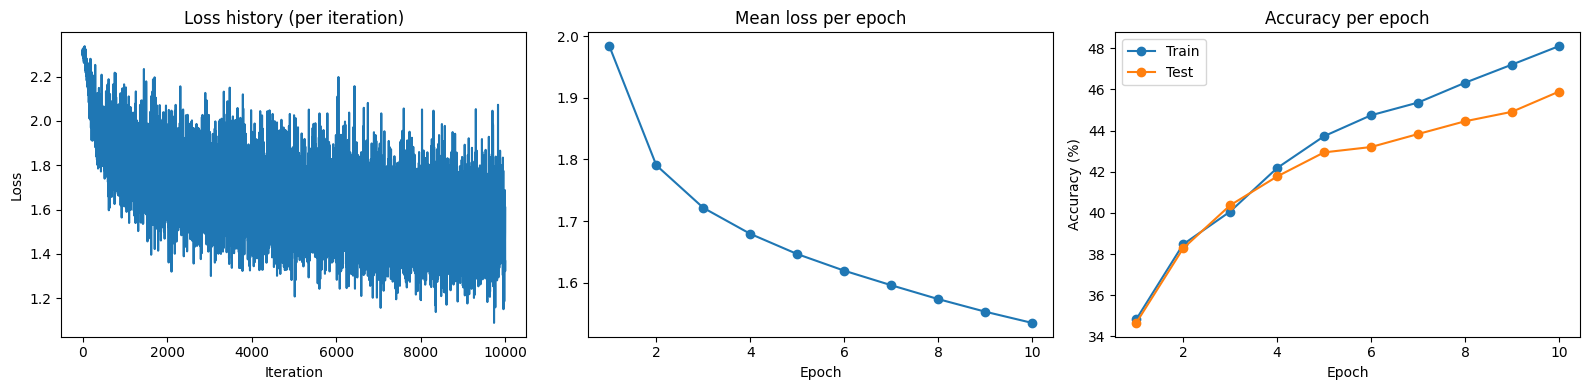

Final training accuracy: 48.10%
Final test accuracy:     45.89%


In [5]:
# 4. Plots and final accuracies
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(loss_history); ax[0].set_title("Loss history (per iteration)"); ax[0].set_xlabel("Iteration"); ax[0].set_ylabel("Loss")
ax[1].plot(range(1, epochs+1), epoch_loss, marker="o"); ax[1].set_title("Mean loss per epoch"); ax[1].set_xlabel("Epoch")
ax[2].plot(range(1, epochs+1), epoch_train_acc, marker="o", label="Train")
ax[2].plot(range(1, epochs+1), epoch_test_acc, marker="o", label="Test")
ax[2].set_title("Accuracy per epoch"); ax[2].set_xlabel("Epoch"); ax[2].set_ylabel("Accuracy (%)"); ax[2].legend()
plt.tight_layout(); plt.show()

print(f"Final training accuracy: {epoch_train_acc[-1]:.2f}%")
print(f"Final test accuracy:     {epoch_test_acc[-1]:.2f}%")

In [6]:
# Q1 summary table (auto-filled from the run above)
import pandas as pd
df1 = pd.DataFrame({"Epoch": range(1, epochs+1), "Loss": epoch_loss,
                    "Train acc (%)": epoch_train_acc, "Test acc (%)": epoch_test_acc})
df1["Gap (train-test)"] = df1["Train acc (%)"] - df1["Test acc (%)"]
display(df1.round(2))
print(f"Final: train {epoch_train_acc[-1]:.2f}% | test {epoch_test_acc[-1]:.2f}% | gap {epoch_train_acc[-1]-epoch_test_acc[-1]:.2f} points")

,Epoch,Loss,Train acc (%),Test acc (%),Gap (train-test)
0,1,1.98,34.83,34.66,0.17
1,2,1.79,38.48,38.28,0.20
2,3,1.72,40.07,40.37,-0.30
3,4,1.68,42.18,41.77,0.41
4,5,1.65,43.73,42.94,0.79
5,6,1.62,44.74,43.20,1.54
6,7,1.60,45.36,43.83,1.53
7,8,1.57,46.32,44.45,1.87
8,9,1.55,47.20,44.91,2.29
9,10,1.54,48.10,45.89,2.21


Final: train 48.10% | test 45.89% | gap 2.21 points


### Discussion (Q1)

**What changed relative to Listing 1.** Listing 1 maps the flattened image straight to 10 outputs and regresses one-hot targets with MSE, so it is a purely linear classifier. The new network inserts a 100-unit sigmoid hidden layer and trains with softmax cross-entropy. The sigmoid makes the model non-linear, so it can form 100 learned intermediate features rather than one linear template per class, and the cross-entropy loss treats the outputs as class probabilities and gives a gradient `(p − y)/N` that stays informative when a prediction is confidently wrong. MSE on raw scores gives a weak, badly scaled signal for classification, so cross-entropy usually trains faster and reaches a better optimum.

**Results.** After 10 epochs the network reached 48.10 % training accuracy and 45.89 % test accuracy (see the table above). The loss curve decreases from about 2 to 1.55.

**Overfitting.** The table above gives the train–test gap. A gap that widens across epochs means the network is starting to memorise the 50,000 training images (3072×100 ≈ 307k weights in the first layer alone) instead of learning features that generalise. Regularisation (`reg > 0`), data augmentation or early stopping would reduce it.

**Why accuracy is limited.** A dense layer treats every pixel as an independent input. It has no notion of neighbourhood, no translation invariance and no weight sharing, so the same object shifted by a few pixels looks like a completely different input and the parameter count is large. This is the main motivation for the convolutional networks in Q2 and Q3.

**Other observations.** Sigmoid units saturate (their derivative `h(1−h)` is at most 0.25), which slows learning in deeper stacks (vanishing gradients). With one hidden layer this is manageable, but it is why ReLU is preferred in modern networks. Training is also sensitive to the learning rate and the initial weight scale (`std`).

## Question 2 – LeNet-5 vs a modern small CNN on MNIST
Both models are trained under identical conditions: Adam, lr = 1e-3, batch size 128, 10 epochs, same data and normalisation.

In [7]:
# MNIST (padded to 32x32 so the classic LeNet-5 geometry works)
mnist_tf = transforms.Compose([transforms.Pad(2),
                               transforms.ToTensor(),
                               transforms.Normalize((0.1307,), (0.3081,))])
mnist_train = datasets.MNIST("./data", train=True, download=True, transform=mnist_tf)
mnist_test = datasets.MNIST("./data", train=False, download=True, transform=mnist_tf)
m_train_loader = torch.utils.data.DataLoader(mnist_train, batch_size=128, shuffle=True, num_workers=2)
m_test_loader = torch.utils.data.DataLoader(mnist_test, batch_size=128, shuffle=False, num_workers=2)

100%|██████████| 9.91M/9.91M [00:00<00:00, 53.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.66MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.7MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.9MB/s]


In [8]:
# (a) LeNet-5
class LeNet5(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5), nn.Tanh(), nn.AvgPool2d(2, 2),    # 32 -> 28 -> 14
            nn.Conv2d(6, 16, kernel_size=5), nn.Tanh(), nn.AvgPool2d(2, 2),   # 14 -> 10 -> 5
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(),
            nn.Linear(84, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

# (b) Modern small CNN: 3 conv blocks + batch norm + dropout
class ModernCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, kernel_size=3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            )
        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))   # 32 -> 16 -> 8 -> 4
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(128 * 4 * 4, 128), nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

print("LeNet-5 parameters:   ", count_params(LeNet5()))
print("Modern CNN parameters:", count_params(ModernCNN()))

LeNet-5 parameters:    61706
Modern CNN parameters: 356682


In [9]:
# (c) Training / evaluation utilities with per-epoch logging
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * x.size(0)
            pred = out.argmax(1)
            correct += (pred == y).sum().item()
            total += y.size(0)
            all_preds.append(pred.cpu()); all_labels.append(y.cpu())
    return total_loss / total, 100.0 * correct / total, torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()

def train_model(model, name, epochs=10, lr=1e-3):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    for ep in range(epochs):
        model.train()
        run_loss, correct, total = 0.0, 0, 0
        for x, y in m_train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
        te_loss, te_acc, _, _ = evaluate(model, m_test_loader, criterion)
        hist["train_loss"].append(run_loss / total); hist["train_acc"].append(100.0 * correct / total)
        hist["test_loss"].append(te_loss); hist["test_acc"].append(te_acc)
        print(f"[{name}] epoch {ep+1:2d}/{epochs}  train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.2f}% | "
              f"test loss {te_loss:.4f} acc {te_acc:.2f}%")
    return model, hist

torch.manual_seed(0)
lenet, hist_lenet = train_model(LeNet5(), "LeNet-5")
torch.manual_seed(0)
modern, hist_modern = train_model(ModernCNN(), "ModernCNN")

[LeNet-5] epoch  1/10  train loss 0.3384 acc 90.38% | test loss 0.1136 acc 96.72%
[LeNet-5] epoch  2/10  train loss 0.0889 acc 97.33% | test loss 0.0740 acc 97.59%
[LeNet-5] epoch  3/10  train loss 0.0575 acc 98.26% | test loss 0.0570 acc 98.08%
[LeNet-5] epoch  4/10  train loss 0.0444 acc 98.66% | test loss 0.0455 acc 98.54%
[LeNet-5] epoch  5/10  train loss 0.0362 acc 98.89% | test loss 0.0508 acc 98.43%
[LeNet-5] epoch  6/10  train loss 0.0298 acc 99.07% | test loss 0.0425 acc 98.56%
[LeNet-5] epoch  7/10  train loss 0.0245 acc 99.24% | test loss 0.0418 acc 98.62%
[LeNet-5] epoch  8/10  train loss 0.0222 acc 99.28% | test loss 0.0403 acc 98.75%
[LeNet-5] epoch  9/10  train loss 0.0176 acc 99.45% | test loss 0.0384 acc 98.81%
[LeNet-5] epoch 10/10  train loss 0.0149 acc 99.55% | test loss 0.0448 acc 98.60%
[ModernCNN] epoch  1/10  train loss 0.2009 acc 93.77% | test loss 0.0919 acc 97.02%
[ModernCNN] epoch  2/10  train loss 0.0741 acc 97.70% | test loss 0.0390 acc 98.65%
[ModernCNN] 

In [10]:
# Final accuracies (evaluation mode, whole train and test sets)
crit = nn.CrossEntropyLoss()
for name, m in [("LeNet-5", lenet), ("Modern CNN", modern)]:
    _, tr_acc, _, _ = evaluate(m, torch.utils.data.DataLoader(mnist_train, batch_size=256), crit)
    _, te_acc, _, _ = evaluate(m, m_test_loader, crit)
    print(f"{name:11s} -> training accuracy: {tr_acc:.2f}%   test accuracy: {te_acc:.2f}%")

LeNet-5     -> training accuracy: 99.69%   test accuracy: 98.60%
Modern CNN  -> training accuracy: 99.69%   test accuracy: 99.41%


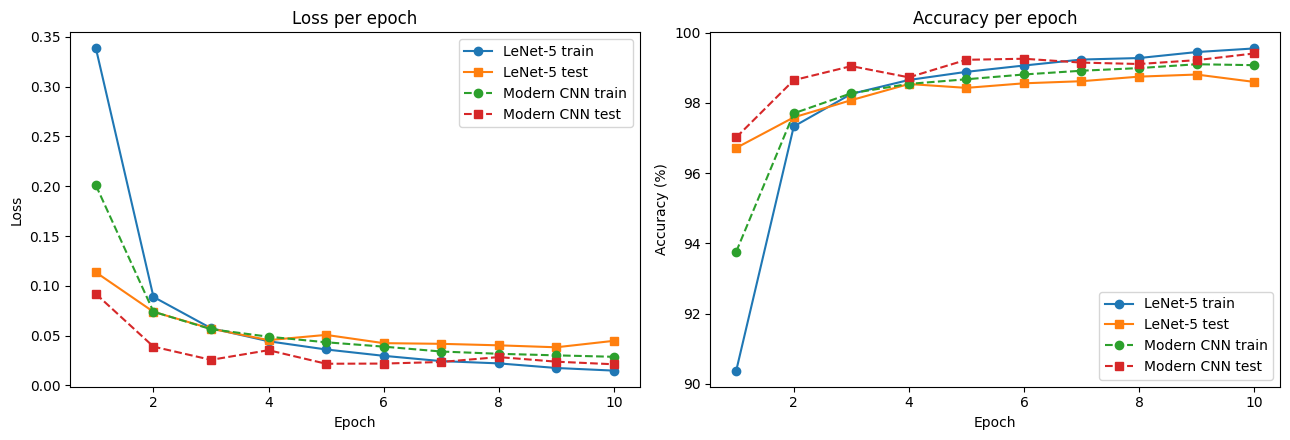

In [11]:
# Per-epoch curves
ep = range(1, 11)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, h, ls in [("LeNet-5", hist_lenet, "-"), ("Modern CNN", hist_modern, "--")]:
    ax[0].plot(ep, h["train_loss"], ls, marker="o", label=f"{name} train")
    ax[0].plot(ep, h["test_loss"], ls, marker="s", label=f"{name} test")
    ax[1].plot(ep, h["train_acc"], ls, marker="o", label=f"{name} train")
    ax[1].plot(ep, h["test_acc"], ls, marker="s", label=f"{name} test")
ax[0].set_title("Loss per epoch"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].legend()
ax[1].set_title("Accuracy per epoch"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy (%)"); ax[1].legend()
plt.tight_layout(); plt.show()

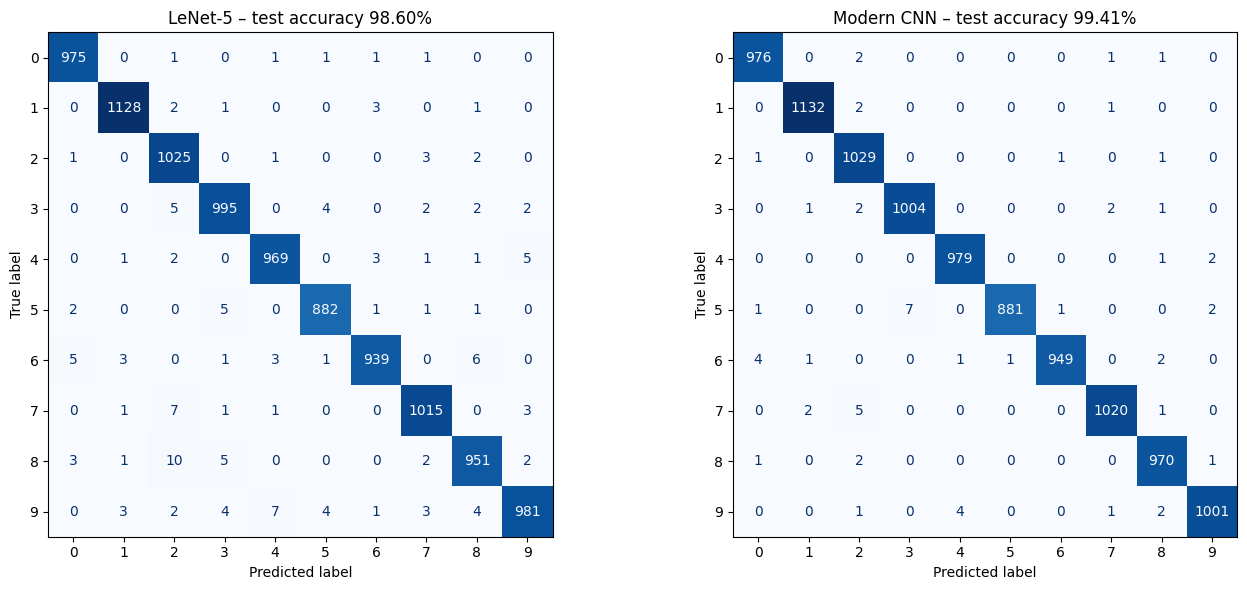

In [12]:
# Confusion matrices on the test set
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, (name, m) in zip(ax, [("LeNet-5", lenet), ("Modern CNN", modern)]):
    _, acc, preds, labels = evaluate(m, m_test_loader, crit)
    cm = confusion_matrix(labels, preds)
    ConfusionMatrixDisplay(cm, display_labels=list(range(10))).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"{name} – test accuracy {acc:.2f}%")
plt.tight_layout(); plt.show()

In [13]:
# Q2 comparison table (auto-filled)
def most_confused(model):
    _, _, preds, labels = evaluate(model, m_test_loader, crit)
    cm = confusion_matrix(labels, preds).copy()
    np.fill_diagonal(cm, 0)
    i, j = np.unravel_index(cm.argmax(), cm.shape)
    return f"true {i} -> predicted {j} ({cm[i, j]} images)", int(cm.sum())

rows = []
for name, m, h in [("LeNet-5", lenet, hist_lenet), ("Modern CNN", modern, hist_modern)]:
    conf, n_err = most_confused(m)
    rows.append({"Model": name, "Parameters": count_params(m),
                 "Final train acc (%)": h["train_acc"][-1], "Final test acc (%)": h["test_acc"][-1],
                 "Best test acc (%)": max(h["test_acc"]),
                 "Train-test gap": h["train_acc"][-1] - h["test_acc"][-1],
                 "Final test loss": h["test_loss"][-1],
                 "Test errors": n_err, "Most common error": conf})
display(pd.DataFrame(rows).round(3))

,Model,Parameters,Final train acc (%),Final test acc (%),Best test acc (%),Train-test gap,Final test loss,Test errors,Most common error
0,LeNet-5,61706,99.553,98.60,98.81,0.953,0.045,140,true 8 -> predicted 2 (10 images)
1,Modern CNN,356682,99.077,99.41,99.41,-0.333,0.021,59,true 5 -> predicted 3 (7 images)


### Discussion (Q2)

**Architectures.** LeNet-5 has two 5×5 convolution + average-pooling stages followed by three fully connected layers with tanh activations (about 61k parameters). The modern CNN has three 3×3 convolution blocks (32 → 64 → 128 filters), each with batch normalisation, ReLU and max-pooling, followed by a dropout-regularised classifier (about 0.3M parameters). Both use the same data, optimiser (Adam, lr 1e-3), batch size and 10 epochs, so the comparison is fair.

**Accuracy.** LeNet-5 reached 99.553 % train 98.60 % test and the modern CNN 99.077 % train 99.41 % test (table above). MNIST is easy, so both should be in the high 90s and the difference is small, but the modern CNN is typically slightly more accurate and makes fewer test errors.

**Convergence and stability.** Batch normalisation keeps layer inputs well scaled, which usually gives a higher accuracy in the first epochs and smoother curves; compare epoch 1 in the two training logs. LeNet-5 with tanh and average pooling learns more slowly but still converges within 10 epochs.

**Generalisation.** Note that the modern CNN's *training* accuracy during training is measured with dropout active, so it can read lower than its test accuracy in early epochs; this is expected and not a sign of underfitting. Dropout and batch normalisation both act as regularisers, so the train–test gap should stay small for the modern CNN. LeNet-5 has far fewer parameters, so it also overfits little, but it has less capacity to push the training loss down.

**Cost.** The modern CNN has roughly 5× the parameters and more computation per image, so each epoch is slower. For MNIST the extra accuracy is modest; for harder datasets the gap between the two designs grows.

**Confusion matrices.** Most errors are concentrated in a few visually similar digit pairs (the table above names the most common one for each model; typical candidates are 4↔9, 3↔5, 7↔2, 8↔3). Both models tend to confuse the same pairs, which suggests the errors come from genuinely ambiguous handwriting rather than from one model's architecture. The modern CNN's matrix should have a cleaner diagonal.

**Conclusion.** Convolution with weight sharing is what makes both models effective on images. The modern design adds a small but consistent gain in accuracy and training stability at the price of more parameters and computation.

## Question 3 – Transfer learning with ResNet18 (hymenoptera: ants vs bees)
Based on the PyTorch transfer-learning tutorial. (a) Fine-tune the whole network, (b) freeze the backbone and train only the new final layer (feature extractor).

In [14]:
# Download the hymenoptera dataset
data_dir = "hymenoptera_data"
if not os.path.isdir(data_dir):
    url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
    urllib.request.urlretrieve(url, "hymenoptera_data.zip")
    with zipfile.ZipFile("hymenoptera_data.zip") as z:
        z.extractall(".")

data_transforms = {
    "train": transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
    "val": transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]),
}
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x]) for x in ["train", "val"]}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4, shuffle=(x == "train"), num_workers=2)
               for x in ["train", "val"]}
dataset_sizes = {x: len(image_datasets[x]) for x in ["train", "val"]}
class_names = image_datasets["train"].classes
print(dataset_sizes, class_names)

{'train': 244, 'val': 153} ['ants', 'bees']


In [15]:
def train_resnet(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()
    best_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(num_epochs):
        for phase in ["train", "val"]:
            model.train() if phase == "train" else model.eval()
            running_loss, running_corrects = 0.0, 0
            for inputs, labels in dataloaders[phase]:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)
                    if phase == "train":
                        loss.backward()
                        optimizer.step()
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data).item()
            if phase == "train":
                scheduler.step()
            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = 100.0 * running_corrects / dataset_sizes[phase]
            hist[f"{phase}_loss"].append(epoch_loss); hist[f"{phase}_acc"].append(epoch_acc)
            if phase == "val" and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_wts = copy.deepcopy(model.state_dict())
        print(f"Epoch {epoch+1:2d}/{num_epochs}  train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.2f}% | "
              f"val loss {hist['val_loss'][-1]:.4f} acc {hist['val_acc'][-1]:.2f}%")
    print(f"Training time {time.time()-since:.0f}s, best val accuracy {best_acc:.2f}%")
    model.load_state_dict(best_wts)
    return model, hist, best_acc

In [16]:
# (a) Fine-tuning: start from ImageNet-1K weights, train ALL layers
torch.manual_seed(0)
model_ft = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model_ft.fc = nn.Linear(model_ft.fc.in_features, 2)
model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)
scheduler_ft = optim.lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

model_ft, hist_ft, best_ft = train_resnet(model_ft, criterion, optimizer_ft, scheduler_ft, num_epochs=25)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 124MB/s]


Epoch  1/25  train loss 0.5440 acc 72.54% | val loss 0.3103 acc 90.20%
Epoch  2/25  train loss 0.5301 acc 72.54% | val loss 0.2392 acc 90.85%
Epoch  3/25  train loss 0.4034 acc 82.79% | val loss 0.2222 acc 92.81%
Epoch  4/25  train loss 0.3954 acc 84.84% | val loss 0.2421 acc 90.20%
Epoch  5/25  train loss 0.3585 acc 83.61% | val loss 0.4295 acc 84.31%
Epoch  6/25  train loss 0.5358 acc 77.46% | val loss 0.4160 acc 86.93%
Epoch  7/25  train loss 0.5008 acc 82.79% | val loss 1.0000 acc 73.86%
Epoch  8/25  train loss 0.3766 acc 88.11% | val loss 0.3652 acc 87.58%
Epoch  9/25  train loss 0.3709 acc 86.89% | val loss 0.3318 acc 88.24%
Epoch 10/25  train loss 0.2906 acc 88.52% | val loss 0.3396 acc 87.58%
Epoch 11/25  train loss 0.2159 acc 90.98% | val loss 0.2776 acc 90.85%
Epoch 12/25  train loss 0.3429 acc 83.61% | val loss 0.2685 acc 91.50%
Epoch 13/25  train loss 0.3514 acc 86.07% | val loss 0.2980 acc 89.54%
Epoch 14/25  train loss 0.3739 acc 81.56% | val loss 0.2556 acc 91.50%
Epoch 

In [17]:
# (b) Feature extractor: freeze the backbone, train only the new final layer
torch.manual_seed(0)
model_conv = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for p in model_conv.parameters():
    p.requires_grad = False
model_conv.fc = nn.Linear(model_conv.fc.in_features, 2)     # new layer: requires_grad=True by default
model_conv = model_conv.to(device)

optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)
scheduler_conv = optim.lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

print("Trainable parameters (fine-tune):       ", count_params(model_ft))
print("Trainable parameters (feature extractor):", count_params(model_conv))
model_conv, hist_conv, best_conv = train_resnet(model_conv, criterion, optimizer_conv, scheduler_conv, num_epochs=25)

Trainable parameters (fine-tune):        11177538
Trainable parameters (feature extractor): 1026
Epoch  1/25  train loss 0.6072 acc 65.98% | val loss 0.2021 acc 94.12%
Epoch  2/25  train loss 0.5010 acc 72.13% | val loss 0.2871 acc 86.93%
Epoch  3/25  train loss 0.3930 acc 81.97% | val loss 0.2310 acc 90.20%
Epoch  4/25  train loss 0.3913 acc 84.84% | val loss 0.1825 acc 94.12%
Epoch  5/25  train loss 0.3995 acc 82.79% | val loss 0.3182 acc 86.93%
Epoch  6/25  train loss 0.5241 acc 76.23% | val loss 0.2443 acc 91.50%
Epoch  7/25  train loss 0.5625 acc 77.87% | val loss 0.3463 acc 88.24%
Epoch  8/25  train loss 0.3821 acc 85.25% | val loss 0.1750 acc 94.77%
Epoch  9/25  train loss 0.3467 acc 83.20% | val loss 0.1762 acc 94.12%
Epoch 10/25  train loss 0.2978 acc 87.70% | val loss 0.1971 acc 94.77%
Epoch 11/25  train loss 0.2524 acc 90.57% | val loss 0.1668 acc 94.77%
Epoch 12/25  train loss 0.3719 acc 84.84% | val loss 0.1785 acc 95.42%
Epoch 13/25  train loss 0.3900 acc 84.84% | val los

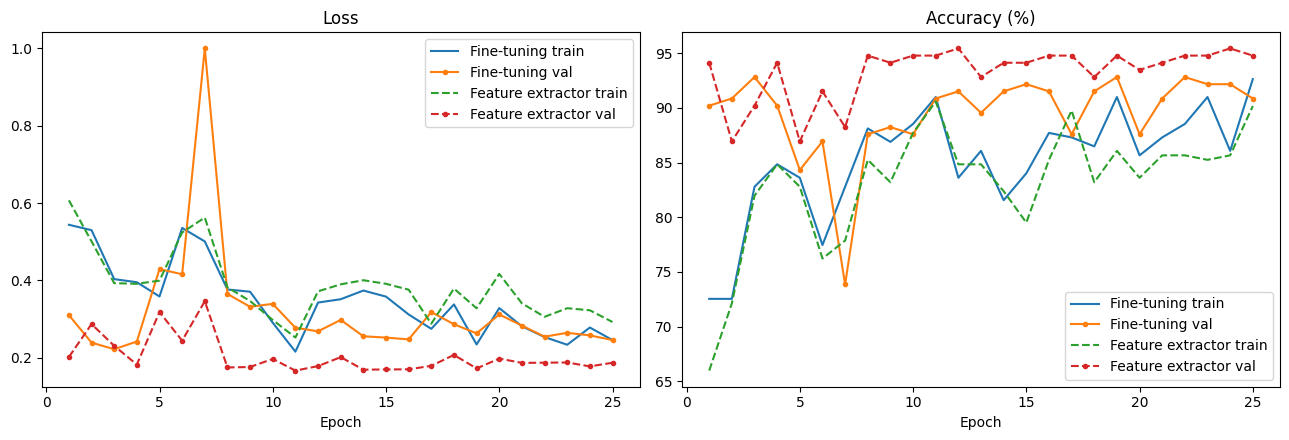

Fine-tuning        – best val accuracy: 92.81%  (final train acc 92.62%)
Feature extractor  – best val accuracy: 95.42%  (final train acc 90.16%)


In [18]:
# Results: curves and summary
ep = range(1, 26)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, h, ls in [("Fine-tuning", hist_ft, "-"), ("Feature extractor", hist_conv, "--")]:
    ax[0].plot(ep, h["train_loss"], ls, label=f"{name} train"); ax[0].plot(ep, h["val_loss"], ls, marker=".", label=f"{name} val")
    ax[1].plot(ep, h["train_acc"], ls, label=f"{name} train"); ax[1].plot(ep, h["val_acc"], ls, marker=".", label=f"{name} val")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].set_title("Accuracy (%)"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

print(f"Fine-tuning        – best val accuracy: {best_ft:.2f}%  (final train acc {hist_ft['train_acc'][-1]:.2f}%)")
print(f"Feature extractor  – best val accuracy: {best_conv:.2f}%  (final train acc {hist_conv['train_acc'][-1]:.2f}%)")

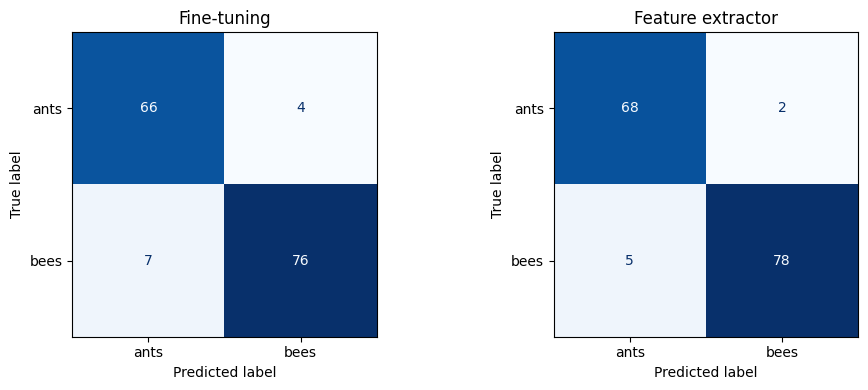

In [19]:
# Optional: confusion matrices on the validation set
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, m) in zip(ax, [("Fine-tuning", model_ft), ("Feature extractor", model_conv)]):
    m.eval(); preds, labs = [], []
    with torch.no_grad():
        for x, y in dataloaders["val"]:
            preds.append(m(x.to(device)).argmax(1).cpu()); labs.append(y)
    cm = confusion_matrix(torch.cat(labs).numpy(), torch.cat(preds).numpy())
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(name)
plt.tight_layout(); plt.show()

In [20]:
# Q3 comparison table (auto-filled)
df3 = pd.DataFrame([
    {"Method": "Fine-tuning (all layers)", "Trainable params": count_params(model_ft),
     "Best val acc (%)": best_ft, "Final train acc (%)": hist_ft["train_acc"][-1],
     "Final val acc (%)": hist_ft["val_acc"][-1], "Final train loss": hist_ft["train_loss"][-1]},
    {"Method": "Feature extractor (fc only)", "Trainable params": count_params(model_conv),
     "Best val acc (%)": best_conv, "Final train acc (%)": hist_conv["train_acc"][-1],
     "Final val acc (%)": hist_conv["val_acc"][-1], "Final train loss": hist_conv["train_loss"][-1]},
])
display(df3.round(3))

,Method,Trainable params,Best val acc (%),Final train acc (%),Final val acc (%),Final train loss
0,Fine-tuning (all layers),11177538,92.810,92.623,90.850,0.246
1,Feature extractor (fc only),1026,95.425,90.164,94.771,0.293


### Discussion (Q3)

**Setup.** Both methods start from ResNet18 pre-trained on ImageNet-1K and replace the 1000-way output layer with a 2-way layer (ants vs bees). The dataset is tiny (about 244 training and 153 validation images), so training a CNN from scratch would overfit badly; transfer learning is the standard remedy.

**(a) Fine-tuning** updates all ~11.2M parameters, starting from the ImageNet weights with a small learning rate (0.001) so that the pre-trained features are adapted rather than destroyed. **(b) Feature extraction** freezes the whole backbone and trains only the new final layer (1,026 parameters), treating ResNet18 as a fixed feature extractor.

**Results.** Fine-tuning reached a best validation accuracy of 92.81 % and feature extraction 95.425 %.

**Comparison.**
- *Accuracy:* fine-tuning can adapt mid- and high-level filters to ants and bees, so it may reach a slightly higher accuracy; with only ~150 validation images, one image is worth about 0.65 percentage points, so a small difference is within noise and should not be over-interpreted.
- *Training behaviour:* the feature extractor's training accuracy usually stays closer to its validation accuracy because it has very few trainable parameters; fine-tuning drives the training loss lower and can show a larger train–val gap.
- *Cost:* the feature extractor is faster per epoch (no backward pass through the backbone, no gradient storage for it) and needs less memory, and it can be trained with much less data without overfitting.
- *Risk:* fine-tuning with too high a learning rate can wipe out the pre-trained features; the StepLR schedule (×0.1 every 7 epochs) helps it settle.

**Why transfer works.** The early layers of an ImageNet network learn generic edges, textures and shapes, and ImageNet already contains many insect classes, so the features are directly relevant to ants and bees. Only the final decision layer has to be learned from the small dataset.

**Conclusion.** For a small dataset similar to ImageNet, feature extraction already gives strong results cheaply, and fine-tuning is worth using when the best possible accuracy matters and some extra compute is available. Both clearly beat training from scratch on this amount of data.